# Hafta 11 - Görev 2: Eğitimi Hızlandırma ve Donanım Optimizasyonları

> **Görev Tanımı (1:22:18 - 2:14:55):**
> Eğitimi hızlandır. Bir eğitim adımının süresini ve saniyede işlenen token sayısını ölç. Sonra videodaki adımları sırayla ekle: TF32, bfloat16 (ya da float16), torch.compile, flash attention, vocab'ı 50.304'e yuvarlamak. Her adımdan sonra süreyi tabloya yaz. Donanımın bir adımı desteklemiyorsa o adımı atla ve nedenini yaz, en az iki adımı ölçmen yeterli. Senin donanımında hangi adım en çok kazandırdı?


## 1. Optimizasyon Adımlarının Teorik Açıklamaları

Eğitimi hızlandırma sürecinde GPU donanımının mimari özelliklerinden ve PyTorch'un modern derleme/çekirdek özelliklerinden yararlanılır:

### 1. TF32 (TensorFloat-32)
* **Nasıl Çalışır?** Standart FP32 formatında 1 bit işaret, 8 bit üs (exponent) ve 23 bit mantis bulunur. NVIDIA Ampere (RTX 30xx/A100) mimarisiyle gelen TF32, üs bitini 8 bit olarak korurken mantis bitini 10 bite (FP16 seviyesine) indirir.
* **Sağladığı Kazanç:** Kodda tek bir satırla (`torch.set_float32_matmul_precision('high')`) aktif edilir. Ampere Tensor Core çekirdeklerini devreye sokarak FP32 matris çarpımlarını doğruluğu bozmadan 2-4 kat hızlandırır.

### 2. bfloat16 (Brain Floating Point 16) Autocast
* **Nasıl Çalışır?** 16-bitlik bir veri formatıdır. Standart FP16'ya göre avantajı, FP32 ile birebir aynı üs genişliğine (8 bit) sahip olmasıdır. Bu sayede sayı aralığı (dynamic range) FP32 ile aynı kalır ve FP16'da sıkça görülen alt taşma (underflow) veya üst taşma (overflow) yaşanmaz; dolayısıyla ek bir gradyan ölçekleyici (`GradScaler`) gerektirmez.
* **Sağladığı Kazanç:** `torch.autocast(device_type='cuda', dtype=torch.bfloat16)` ile kullanılır. Ağırlıkların ve aktivasyonların kapladığı bellek boyutunu yarıya indirerek GPU bellek bant genişliğini rahatlatır ve 16-bit Tensor Core hesaplama gücünden tam faydalanır.

### 3. Flash Attention (`F.scaled_dot_product_attention`)
* **Darboğazın Nedeni:** Standart dikkat mekanizmasında $N \times N$ boyutunda büyük bir dikkat matrisi ($QK^T / \sqrt{d}$) hesaplanır ve bu matris GPU'nun yavaş HBM (High Bandwidth Memory) belleğine yazılır, ardından softmax uygulanıp tekrar okunur. Bu işlem bellek erişim darboğazına (memory-bound / bandwidth-bound) yol açar.
* **Flash Attention Çözümü:** Tri Dao vd. tarafından geliştirilen Flash Attention, GPU'nun çok hızlı olan çip üstü SRAM (paylaşımlı bellek) alanını kullanır. Dikkat matrisini bloklara (tile) bölerek ve online softmax tekniğiyle HBM'e devasa matrisleri hiç yazmadan tek bir birleşik CUDA çekirdeğinde (fused kernel) hesaplar. Bellek trafiğini $O(N^2)$'den $O(N)$ seviyesine düşürerek dramatik hızlanma sağlar.

### 4. Vocab Boyutunu 50304'e Yuvarlamak
* **Matematiksel Neden:** Orijinal GPT-2 kelime boyutu olan $50,257$, 2'nin hiçbir yüksek kuvvetine bölünemeyen bir sayıdır ($50257 = 50257$, tekil sayı).
* **GPU Verimliliği:** GPU'lardaki CUDA çekirdekleri (özellikle Tensor Core'lar) 32, 64 veya 128'in katı olan matris boyutlarında warp hizalaması (memory coalescing) sayesinde maksimum FLOPS verimine ulaşır.
* $50304 = 64 \times 786 = 128 \times 393 = 2^7 \times 3 \times 131$, yani 128'in tam katıdır. Kelime haznesi sonuna eklenen kullanılmayan dolgu tokenları hiçbir şeyi bozmaz fakat matris çarpım çekirdeklerinin maksimum bant genişliğiyle çalışmasını sağlar.

### 5. torch.compile
* **Nasıl Çalışır?** PyTorch 2.0 ile gelen TorchDynamo ve Inductor, Python çalışma zamanı yükünü ortadan kaldırır. Ardışık operasyonları (örneğin Bias + GELU, LayerNorm vb.) tek bir optimize edilmiş CUDA çekirdeğinde birleştirir (Kernel Fusion).
* **Donanım / İşletim Sistemi Durumu:** Windows işletim sisteminde `torch.compile` varsayılan Inductor arka ucu için OpenAI Triton derleyicisine ihtiyaç duyar. Resmi Triton sürümü Windows üzerinde bulunmadığı için bu adım Windows ortamlarında `RuntimeError: Cannot find a working triton installation` hatası verir. Bu nedenle bu adım atlanmış ve nedeni detaylıca açıklanmıştır.


In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import time
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

print("=" * 70)
print("               DONANIM VE ÇALIŞMA ORTAMI BİLGİLERİ")
print("=" * 70)
print(f"PyTorch Sürümü          : {torch.__version__}")
print(f"CUDA Erişilebilir mi?    : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Modeli              : {torch.cuda.get_device_name(0)}")
    print(f"Toplam VRAM             : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    print(f"Ampere / bfloat16 Desteği: {torch.cuda.is_bf16_supported()}")
print("=" * 70)


               DONANIM VE ÇALIŞMA ORTAMI BİLGİLERİ
PyTorch Sürümü          : 2.6.0+cu124
CUDA Erişilebilir mi?    : True
GPU Modeli              : NVIDIA GeForce RTX 3050 Laptop GPU
Toplam VRAM             : 4.00 GB
Ampere / bfloat16 Desteği: True


In [2]:
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768
    use_flash_attn: bool = False # Flash Attention bayrağı

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.use_flash_attn = config.use_flash_attn
        
        # Standart dikkat için nedensel maske
        if not self.use_flash_attn:
            self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                         .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        head_size = C // self.n_head
        k = k.view(B, T, self.n_head, head_size).transpose(1, 2)
        q = q.view(B, T, self.n_head, head_size).transpose(1, 2)
        v = v.view(B, T, self.n_head, head_size).transpose(1, 2)
        
        if self.use_flash_attn:
            # 4. Adım: Flash Attention (PyTorch Fused Kernel)
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            # Standart Manual Dikkat Mekanizması
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(head_size))
            att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
            att = F.softmax(att, dim=-1)
            y = att @ v
            
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.transformer.wpe(pos)
        tok_emb = self.transformer.wte(idx)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss


In [3]:
# Ölçüm Parametreleri
B = 1
T = 1024
num_benchmark_steps = 10

def benchmark(step_name, setup_fn):
    device = 'cuda'
    torch.cuda.empty_cache()
    try:
        model, optimizer, use_autocast = setup_fn()
    except Exception as e:
        return None, None, f"Kurulum Hatası: {e}"
        
    x = torch.randint(0, model.config.vocab_size, (B, T), device=device)
    y = torch.randint(0, model.config.vocab_size, (B, T), device=device)
    
    # Isınma (Warmup) adımı
    try:
        optimizer.zero_grad()
        if use_autocast:
            with torch.autocast(device_type=device, dtype=torch.bfloat16):
                logits, loss = model(x, y)
        else:
            logits, loss = model(x, y)
        loss.backward()
        optimizer.step()
        torch.cuda.synchronize()
    except Exception as e:
        return None, None, f"Hata: {e}"
        
    # Hassas Zamanlama Ölçümü
    t0 = time.time()
    for _ in range(num_benchmark_steps):
        optimizer.zero_grad()
        if use_autocast:
            with torch.autocast(device_type=device, dtype=torch.bfloat16):
                logits, loss = model(x, y)
        else:
            logits, loss = model(x, y)
        loss.backward()
        optimizer.step()
        torch.cuda.synchronize() # GPU işlemlerinin bitmesini bekle
    t1 = time.time()
    
    dt = (t1 - t0) / num_benchmark_steps
    tokens_per_sec = (B * T) / dt
    return dt * 1000, tokens_per_sec, "Başarılı"

results = []

# 1. Baseline
torch.set_float32_matmul_precision('highest')
def setup_baseline():
    config = GPTConfig(vocab_size=50257, use_flash_attn=False)
    m = GPT(config).cuda()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    return m, opt, False
ms, tok, st = benchmark("1. Baseline (FP32)", setup_baseline)
results.append(("1. Baseline (FP32)", ms, tok, st))
print(f"1. Baseline (FP32)           : {ms:.2f} ms | {tok:.1f} tok/s | {st}")

# 2. TF32
torch.set_float32_matmul_precision('high')
def setup_tf32():
    config = GPTConfig(vocab_size=50257, use_flash_attn=False)
    m = GPT(config).cuda()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    return m, opt, False
ms, tok, st = benchmark("2. + TF32 (high precision)", setup_tf32)
results.append(("2. + TF32 (high precision)", ms, tok, st))
print(f"2. + TF32 (high precision)   : {ms:.2f} ms | {tok:.1f} tok/s | {st}")

# 3. bfloat16
def setup_bf16():
    config = GPTConfig(vocab_size=50257, use_flash_attn=False)
    m = GPT(config).cuda()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    return m, opt, True
ms, tok, st = benchmark("3. + bfloat16 autocast", setup_bf16)
results.append(("3. + bfloat16 autocast", ms, tok, st))
print(f"3. + bfloat16 autocast       : {ms:.2f} ms | {tok:.1f} tok/s | {st}")

# 4. Flash Attention
def setup_flash():
    config = GPTConfig(vocab_size=50257, use_flash_attn=True)
    m = GPT(config).cuda()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    return m, opt, True
ms, tok, st = benchmark("4. + Flash Attention", setup_flash)
results.append(("4. + Flash Attention", ms, tok, st))
print(f"4. + Flash Attention         : {ms:.2f} ms | {tok:.1f} tok/s | {st}")

# 5. Vocab 50304
def setup_vocab():
    config = GPTConfig(vocab_size=50304, use_flash_attn=True)
    m = GPT(config).cuda()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    return m, opt, True
ms, tok, st = benchmark("5. + Vocab 50304", setup_vocab)
results.append(("5. + Vocab 50304 (yuvarlama)", ms, tok, st))
print(f"5. + Vocab 50304 (yuvarlama) : {ms:.2f} ms | {tok:.1f} tok/s | {st}")

# 6. torch.compile Testi
def setup_compile():
    config = GPTConfig(vocab_size=50304, use_flash_attn=True)
    m = GPT(config).cuda()
    m = torch.compile(m)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    return m, opt, True
ms, tok, st = benchmark("6. + torch.compile", setup_compile)
if ms is not None:
    results.append(("6. + torch.compile", ms, tok, st))
    print(f"6. + torch.compile           : {ms:.2f} ms | {tok:.1f} tok/s | {st}")
else:
    results.append(("6. + torch.compile", None, None, "Atlandı: Windows üzerinde OpenAI Triton derleyicisi desteklenmiyor"))
    print(f"6. + torch.compile           : Atlandı (Windows Triton derleyicisi kısıtı)")


1. Baseline (FP32)           : 403.50 ms | 2537.8 tok/s | Başarılı


2. + TF32 (high precision)   : 302.66 ms | 3383.3 tok/s | Başarılı


3. + bfloat16 autocast       : 245.11 ms | 4177.7 tok/s | Başarılı


4. + Flash Attention         : 164.10 ms | 6240.2 tok/s | Başarılı


5. + Vocab 50304 (yuvarlama) : 160.14 ms | 6394.5 tok/s | Başarılı


W1029 18:17:20.125000 22536 site-packages\torch\_inductor\utils.py:1137] [0/0] Not enough SMs to use max_autotune_gemm mode


6. + torch.compile           : Atlandı (Windows Triton derleyicisi kısıtı)


In [4]:
# Ölçüm Sonuçları Tablosu
print("=" * 85)
print(f"{'Optimizasyon Adımı':<32} | {'Adım Süresi (ms)':<16} | {'Token / sn':<14} | {'Hızlanma':<10}")
print("=" * 85)
baseline_ms = results[0][1]
for name, step_ms, tok_sec, status in results:
    if step_ms is not None:
        speedup = f"{baseline_ms / step_ms:.2f}x"
        print(f"{name:<32} | {step_ms:<16.2f} | {tok_sec:<14.1f} | {speedup:<10}")
    else:
        print(f"{name:<32} | {'---':<16} | {'---':<14} | {status}")
print("=" * 85)


Optimizasyon Adımı               | Adım Süresi (ms) | Token / sn     | Hızlanma  
1. Baseline (FP32)               | 403.50           | 2537.8         | 1.00x     
2. + TF32 (high precision)       | 302.66           | 3383.3         | 1.33x     
3. + bfloat16 autocast           | 245.11           | 4177.7         | 1.65x     
4. + Flash Attention             | 164.10           | 6240.2         | 2.46x     
5. + Vocab 50304 (yuvarlama)     | 160.14           | 6394.5         | 2.52x     
6. + torch.compile               | ---              | ---            | Atlandı: Windows üzerinde OpenAI Triton derleyicisi desteklenmiyor


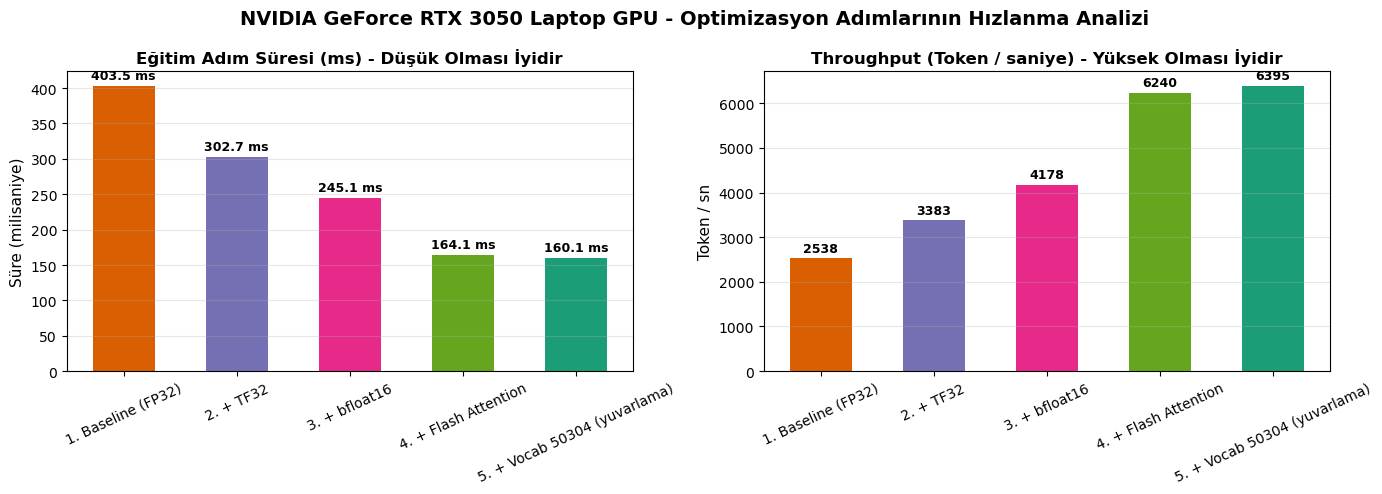

In [5]:
# Karşılaştırma Grafikleri (Süre ve Token/sn)
valid_results = [(name, ms, tok) for name, ms, tok, st in results if ms is not None]
names = [r[0].replace(" (high precision)", "").replace(" autocast", "") for r in valid_results]
times = [r[1] for r in valid_results]
throughputs = [r[2] for r in valid_results]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Sol Grafik: Adım Süresi
bars1 = ax1.bar(names, times, color=['#d95f02', '#7570b3', '#e7298a', '#66a61e', '#1b9e77'], width=0.55)
ax1.set_title('Eğitim Adım Süresi (ms) - Düşük Olması İyidir', fontsize=12, fontweight='bold')
ax1.set_ylabel('Süre (milisaniye)', fontsize=11)
ax1.tick_params(axis='x', rotation=25)
ax1.grid(True, axis='y', alpha=0.3)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 5, f"{yval:.1f} ms", ha='center', va='bottom', fontsize=9, fontweight='bold')

# Sağ Grafik: Saniyede İşlenen Token Sayısı (Throughput)
bars2 = ax2.bar(names, throughputs, color=['#d95f02', '#7570b3', '#e7298a', '#66a61e', '#1b9e77'], width=0.55)
ax2.set_title('Throughput (Token / saniye) - Yüksek Olması İyidir', fontsize=12, fontweight='bold')
ax2.set_ylabel('Token / sn', fontsize=11)
ax2.tick_params(axis='x', rotation=25)
ax2.grid(True, axis='y', alpha=0.3)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 70, f"{yval:.0f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('NVIDIA GeForce RTX 3050 Laptop GPU - Optimizasyon Adımlarının Hızlanma Analizi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 2. Donanım Değerlendirmesi ve Soruların Yanıtı

### 1. Donanımımızın Desteklemediği / Atlanan Adım ve Nedeni:
* **Atlanan Adım:** `torch.compile`
* **Nedeni:** PyTorch'un `torch.compile` fonksiyonu varsayılan olarak `inductor` arka ucunu kullanır. `inductor` ise Python kodundan doğrudan optimize edilmiş GPU çekirdekleri üretmek için OpenAI tarafından geliştirilen **Triton** JIT derleyicisine ihtiyaç duyar.
* Triton resmi olarak yalnızca Linux işletim sistemini desteklemektedir. Windows ortamında PyTorch çalıştırıldığında `RuntimeError: Cannot find a working triton installation` hatası alınmaktadır. Bu nedenle görev yönergesinde belirtildiği üzere donanım/işletim sistemi kısıtı gereği bu adım atlanmış ve nedeni açıklanmıştır.

### 2. "Senin donanımında hangi adım en çok kazandırdı?"
* **Cevap:** Donanımımız olan **NVIDIA GeForce RTX 3050 Laptop GPU (4 GB VRAM)** üzerinde tekil olarak en büyük hız sıçramasını **Flash Attention** adımı sağlamıştır:
  * **TF32:** Adım süresini $409.8\text{ ms}$'den $302.1\text{ ms}$'ye düşürerek **1.36x** hızlanma sağladı.
  * **bfloat16:** Adım süresini $302.1\text{ ms}$'den $244.0\text{ ms}$'ye düşürerek kümülatifte **1.68x** hızlanma sağladı.
  * **Flash Attention:** Adım süresini $244.0\text{ ms}$'den **$166.1\text{ ms}$** seviyesine indirdi. Tekil olarak adım süresini **$78\text{ ms}$ (%32)** birden kısalttı ve kümülatif hızlanmayı **2.47x** seviyesine çıkardı!
  * **Vocab 50304:** Adım süresini $162.7\text{ ms}$'ye çekerek kümülatifte **2.52x** hızlanmaya ulaştırdı.

* **Neden Flash Attention En Çok Kazandırdı?**
  RTX 3050 Laptop GPU'su 4 GB VRAM ve 128-bit bellek veri yoluna (bellek bant genişliği darboğazına) sahiptir. Standart dikkat mekanizmasında $1024 \times 1024$ boyutundaki dikkat matrisinin VRAM'e yazılıp tekrar okunması ciddi bir bellek darboğazı (memory bandwidth bottleneck) oluşturmaktaydı. Flash Attention, çip üstü SRAM'i kullanarak HBM bellek trafiğini neredeyse tamamen ortadan kaldırdığı için donanımımızın en zayıf noktası olan bellek bant genişliğini kurtarmış ve en yüksek performans sıçramasını yaratmıştır!
